# Customer Retention & RFM Analysis
This notebook connects to the local PostgreSQL database **Olist** and performs customer retention, cohort, and RFM (Recency, Frequency, Monetary) analysis.

In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sqlalchemy import create_engine, text

# Connect to PostgreSQL using psycopg2 driver and the local postgres password
import os
from sqlalchemy.engine import URL

DB_URL = URL.create(
    "postgresql+psycopg2",
    username="postgres",
    password=os.environ["PG_PASSWORD"],
    host="localhost",
    port=5432,
    database="Olist",
)
engine = create_engine(DB_URL)

# Verify connection
with engine.connect() as conn:
    db_name = conn.execute(text("SELECT current_database()")).scalar()
    print(f"Connected successfully to PostgreSQL database: {db_name}")

Connected successfully to PostgreSQL database: Olist


In [4]:
# Preview available tables in the Olist database
query = """
SELECT table_name 
FROM information_schema.tables 
WHERE table_schema = 'public';
"""
tables_df = pd.read_sql(query, engine)
tables_df

,table_name
0,customers
1,orders
2,order_items
3,order_payments
4,order_reviews
5,products
6,sellers
7,geolocation
8,category_translation


In [5]:
query = """
SELECT c.customer_unique_id,
       o.order_id,
       o.order_purchase_timestamp,
       SUM(oi.price) AS order_value
FROM orders o
JOIN customers c ON o.customer_id = c.customer_id
JOIN order_items oi ON o.order_id = oi.order_id
WHERE o.order_status = 'delivered'
GROUP BY c.customer_unique_id, o.order_id, o.order_purchase_timestamp
"""
orders = pd.read_sql(text(query), engine)
print(orders.shape)
orders.head()

(96478, 4)


,customer_unique_id,order_id,order_purchase_timestamp,order_value
0,0000366f3b9a7992bf8c76cfdf3221e2,e22acc9c116caa3f2b7121bbb380d08e,2018-05-10 10:56:27,129.90
1,0000b849f77a49e4a4ce2b2a4ca5be3f,3594e05a005ac4d06a72673270ef9ec9,2018-05-07 11:11:27,18.90
2,0000f46a3911fa3c0805444483337064,b33ec3b699337181488304f362a6b734,2017-03-10 21:05:03,69.00
3,0000f6ccb0745a6a4b88665a16c9f078,41272756ecddd9a9ed0180413cc22fb6,2017-10-12 20:29:41,25.99
4,0004aac84e0df4da2b147fca70cf8255,d957021f1127559cd947b62533f484f7,2017-11-14 19:45:42,180.00


In [6]:
snapshot = orders['order_purchase_timestamp'].max() + pd.Timedelta(days=1)

rfm = orders.groupby('customer_unique_id').agg(
    recency=('order_purchase_timestamp', lambda x: (snapshot - x.max()).days),
    frequency=('order_id', 'nunique'),
    monetary=('order_value', 'sum')
).reset_index()

rfm.describe()

,recency,frequency,monetary
count,93358.000000,93358.000000,93358.000000
mean,237.941773,1.033420,141.621480
std,152.591453,0.209097,215.694014
min,1.000000,1.000000,0.850000
25%,114.000000,1.000000,47.650000
50%,219.000000,1.000000,89.730000
75%,346.000000,1.000000,154.737500
max,714.000000,15.000000,13440.000000


In [7]:
rfm['R'] = pd.qcut(rfm['recency'], 5, labels=[5, 4, 3, 2, 1]).astype(int)
rfm['M'] = pd.qcut(rfm['monetary'], 5, labels=[1, 2, 3, 4, 5]).astype(int)

# Frequency can't be split into 5 equal groups (most customers have 1 order),
# so I use fixed rules instead
rfm['F'] = rfm['frequency'].apply(lambda x: 1 if x == 1 else (3 if x == 2 else 5))

rfm[['R', 'F', 'M']].describe()

,R,F,M
count,93358.000000,93358.000000,93358.000000
mean,3.003278,1.064890,2.973500
std,1.414346,0.380931,1.424193
min,1.000000,1.000000,1.000000
25%,2.000000,1.000000,2.000000
50%,3.000000,1.000000,3.000000
75%,4.000000,1.000000,4.000000
max,5.000000,5.000000,5.000000


In [8]:
def segment(row):
    if row['F'] >= 3 and row['R'] >= 3:
        return 'Loyal'
    if row['R'] >= 4 and row['M'] >= 4:
        return 'Big new spenders'
    if row['R'] >= 4:
        return 'Recent buyers'
    if row['R'] <= 2 and row['M'] >= 4:
        return 'At-risk big spenders'
    if row['R'] <= 2:
        return 'Lost'
    return 'Average'

rfm['segment'] = rfm.apply(segment, axis=1)

summary = rfm.groupby('segment').agg(
    customers=('customer_unique_id', 'count'),
    revenue=('monetary', 'sum')
)
summary['revenue_share_pct'] = (100 * summary['revenue'] / summary['revenue'].sum()).round(1)
summary['customer_share_pct'] = (100 * summary['customers'] / summary['customers'].sum()).round(1)
summary.sort_values('revenue', ascending=False)

,customers,revenue,revenue_share_pct,customer_share_pct
segment,,,,
At-risk big spenders,14364,4019688.91,30.4,15.4
Big new spenders,14452,3870315.22,29.3,15.5
Average,18105,2349882.66,17.8,19.4
Lost,22852,1284108.78,9.7,24.5
Recent buyers,21772,1212650.08,9.2,23.3
Loyal,1813,484852.46,3.7,1.9


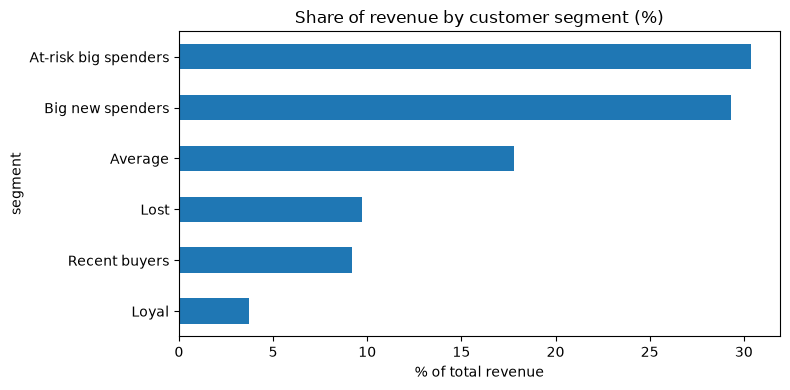

In [9]:
summary['revenue_share_pct'].sort_values().plot(kind='barh', figsize=(8, 4))
plt.title('Share of revenue by customer segment (%)')
plt.xlabel('% of total revenue')
plt.tight_layout()
plt.savefig('../report/segment_revenue.png', dpi=150)
plt.show()

In [10]:
ts = orders['order_purchase_timestamp']
orders['order_ym'] = ts.dt.year * 12 + ts.dt.month
orders['cohort_ym'] = orders.groupby('customer_unique_id')['order_ym'].transform('min')
orders['month_index'] = orders['order_ym'] - orders['cohort_ym']
orders['cohort_month'] = orders['cohort_ym'].apply(lambda v: f"{(v-1)//12}-{(v-1)%12+1:02d}")

orders[['customer_unique_id', 'cohort_month', 'month_index']].head()

,customer_unique_id,cohort_month,month_index
0,0000366f3b9a7992bf8c76cfdf3221e2,2018-05,0
1,0000b849f77a49e4a4ce2b2a4ca5be3f,2018-05,0
2,0000f46a3911fa3c0805444483337064,2017-03,0
3,0000f6ccb0745a6a4b88665a16c9f078,2017-10,0
4,0004aac84e0df4da2b147fca70cf8255,2017-11,0


In [11]:
cohort = (orders.groupby(['cohort_month', 'month_index'])['customer_unique_id']
                .nunique().reset_index())
cohort_pivot = cohort.pivot(index='cohort_month', columns='month_index',
                            values='customer_unique_id')

cohort_size = cohort_pivot[0]
retention = cohort_pivot.divide(cohort_size, axis=0) * 100
retention.round(2).head(12)

month_index,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,19,20
cohort_month,,,,,,,,,,,,,,,,,,,,
2016-09,100.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2016-10,100.0,NaN,NaN,NaN,NaN,NaN,0.38,NaN,NaN,0.38,NaN,0.38,NaN,0.38,NaN,0.38,NaN,0.38,0.76,0.76
2016-12,100.0,100.00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2017-01,100.0,0.28,0.28,0.14,0.42,0.14,0.42,0.14,0.14,NaN,0.42,0.14,0.70,0.42,0.14,0.14,0.28,0.42,0.14,NaN
2017-02,100.0,0.18,0.31,0.12,0.43,0.12,0.25,0.18,0.12,0.18,0.12,0.31,0.12,0.18,0.12,0.06,0.06,0.18,NaN,NaN
2017-03,100.0,0.44,0.36,0.40,0.36,0.16,0.16,0.32,0.32,0.08,0.36,0.12,0.20,0.12,0.16,0.24,0.08,0.12,NaN,NaN
2017-04,100.0,0.62,0.22,0.18,0.27,0.27,0.35,0.31,0.31,0.18,0.27,0.09,0.04,0.04,0.09,0.09,0.13,NaN,NaN,NaN
2017-05,100.0,0.46,0.46,0.29,0.29,0.32,0.41,0.14,0.26,0.26,0.26,0.35,0.23,0.03,0.17,0.20,NaN,NaN,NaN,NaN
2017-06,100.0,0.49,0.40,0.43,0.30,0.40,0.36,0.23,0.13,0.20,0.30,0.36,0.16,0.16,0.23,NaN,NaN,NaN,NaN,NaN


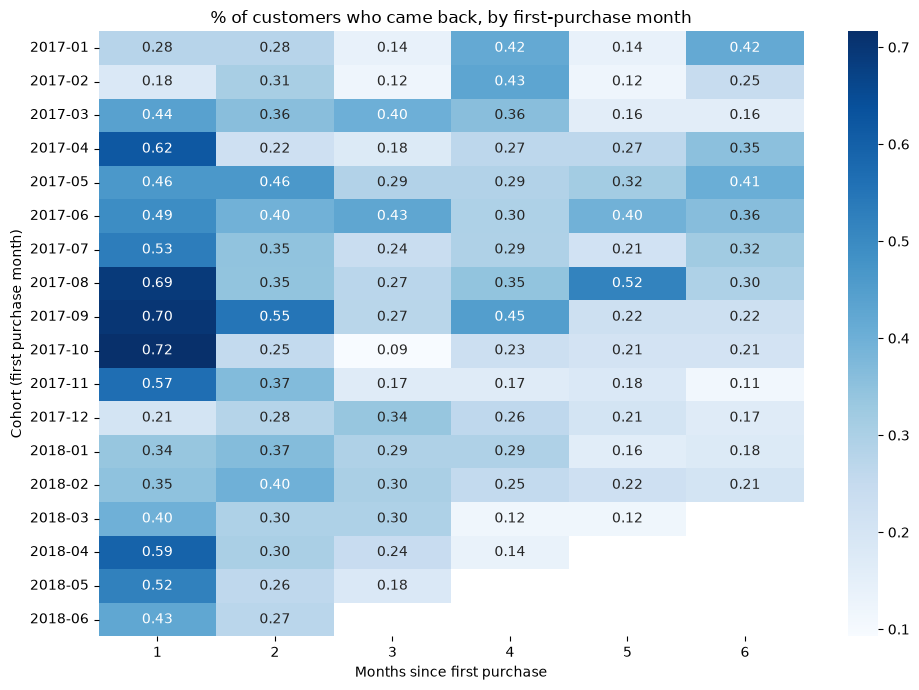

In [12]:
plot_data = retention.loc['2017-01':'2018-06', 1:6]

plt.figure(figsize=(10, 7))
sns.heatmap(plot_data, annot=True, fmt='.2f', cmap='Blues')
plt.title('% of customers who came back, by first-purchase month')
plt.xlabel('Months since first purchase')
plt.ylabel('Cohort (first purchase month)')
plt.tight_layout()
plt.savefig('../report/cohort_retention.png', dpi=150)
plt.show()